# Бинарная модель CatBoost
## 1. Подготовка данных
Читаем готовую кадровую витрину `data/teachers.parquet`: одна строка — педагог в году.
Цель `target=1` — отсутствие в следующем срезе системы, `target=0` — присутствие,
включая переход в другую школу. В 2024 исход неизвестен.

Ноутбук содержит подготовку, подбор Optuna, обучение, оценку и экспорт модели.
Артефакты сохраняются в корневую папку `models/` независимо от рабочей папки.
Dash загружает `models/catboost_churn.cbm` и `models/metadata.json`.
Артефакты `artifacts.pkl` и `forecast_2024.parquet` сохранены как результаты прежнего запуска;
приложение их не читает. Границы риска в Dash — 0,25/0,50; подобранный ниже порог
используется только для оценки эксперимента.
Запускать из корня проекта или папки `notebooks/`, выбрав Python из `.venv`.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

root = Path.cwd()
if not (root / 'dashboard/app.py').is_file():
    root = root.parent

df = pd.read_parquet(root / 'data/teachers.parquet')
assert not df.duplicated(['id', 'year']).any()
display(df.groupby('year')['target'].agg(['size', 'count', 'mean']))

,size,count,mean
year,,,
2022,17396,17396,0.149230
2023,17394,17394,0.132172
2024,17933,0,NaN


### Признаки
Все нужные признаки уже есть в parquet. Выбираем их здесь, без импорта кода дашборда.
Идентификаторы и исходы в признаки не входят. Числовые признаки включают бинарные 0/1.

Категориальные столбцы в готовой витрине уже строковые и не имеют пропусков.
Числовые NaN сохраняем: CatBoost умеет с ними работать. Дополнительные признаки,
One-Hot Encoding, масштабирование и заполнение пропусков здесь не нужны.

In [2]:
numeric = [
    'age', 'experience_age_pedagogic_clean', 'experience_age_other_clean',
    'n_subjects', 'n_parallels', 'min_parallel', 'max_parallel',
    'sex', 'class_manager', 'edu_higher', 'edu_pedagogical', 'edu_speciality_match',
    'pk_recent', 'pk_this_year', 'pk_hours_3y', 'retraining',
]
categorical = ['main_position_cat', 'academic_degree_cat', 'category_qual_cat', 'district', 'speciality']
features = numeric + categorical

assert df[categorical].notna().all().all()
display(df[features].dtypes.to_frame('Тип признака'))

,Тип признака
age,int64
experience_age_pedagogic_clean,int64
experience_age_other_clean,int64
n_subjects,int64
n_parallels,int64
min_parallel,int64
max_parallel,int64
sex,int64
class_manager,int64
edu_higher,int64


### Разделение по годам
2022 — обучение, 2023 — итоговый тест. Данные 2024 готовим отдельно для будущего прогноза,
не заполняя неизвестную цель нулями. Ключи `id, year` сохраняем для сопоставления прогнозов.

In [3]:
train = df[df['year'] == 2022]
test = df[df['year'] == 2023]
forecast = df[df['year'] == 2024]

assert not train.empty and not test.empty and not forecast.empty
assert train['target'].isin([0, 1]).all() and test['target'].isin([0, 1]).all()
assert forecast['target'].isna().all()

X_train, y_train = train[features].copy(), train['target'].astype(int)
X_test, y_test = test[features].copy(), test['target'].astype(int)
X_forecast = forecast[features].copy()
forecast_keys = forecast[['id', 'year']].copy()

display(X_train.isna().sum().loc[lambda s: s > 0].to_frame('Пропусков в train'))

,Пропусков в train
edu_speciality_match,16904


### Validation для будущего подбора параметров
Как в HW8, выделяем 20% 2022 года с сохранением доли классов.
`X_fit, y_fit` будут использоваться для обучения при подборе,
`X_valid, y_valid` — для Optuna и early stopping.
2023 не участвует в выборе параметров; 2024 не участвует ни в обучении, ни в проверке.

In [4]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42,
)

display(pd.DataFrame({
    'Строк': [len(X_fit), len(X_valid), len(X_test), len(X_forecast)],
    'Признаков': [len(features)] * 4,
    'Доля уходов': [y_fit.mean(), y_valid.mean(), y_test.mean(), pd.NA],
}, index=['Обучение 2022', 'Validation 2022', 'Тест 2023', 'Прогноз 2024']))

,Строк,Признаков,Доля уходов
Обучение 2022,13916,21,0.149253
Validation 2022,3480,21,0.149138
Тест 2023,17394,21,0.132172
Прогноз 2024,17933,21,<NA>


Данные готовы. Для следующего этапа доступны `X_fit`, `X_valid`, `X_train`, `X_test`,
соответствующие цели `y_fit`, `y_valid`, `y_train`, `y_test`, а также `X_forecast` и `forecast_keys`.
Список признаков — `features`, категориальных столбцов для CatBoost — `categorical`.
Далее в этом ноутбуке выполняются Optuna, обучение, оценка и сохранение.
Ячейки подготовки выше не записывают данные или файлы модели.

# Модель: прогноз ухода педагога (target)

**Задача:** бинарная классификация — уйдёт педагог в следующем году или останется.  
**Модель:** CatBoost Classifier.  
**Сплит:** временной (обучаемся на ранних годах, валидируем на поздних).  
**Данные:** `teachers.parquet`, зерно `id + year`.

In [5]:
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    precision_recall_curve,
    auc as pr_auc,
)
import numpy as np
from pathlib import Path
import json

MODEL_DIR = root / "models"
MODEL_DIR.mkdir(exist_ok=True)

cat_indices = [features.index(c) for c in categorical]

train_pool_fit = Pool(X_fit, y_fit, cat_features=cat_indices)
valid_pool = Pool(X_valid, y_valid, cat_features=cat_indices)
train_pool_full = Pool(X_train, y_train, cat_features=cat_indices)
test_pool = Pool(X_test, y_test, cat_features=cat_indices)

print(f"Fit: {X_fit.shape}, Valid: {X_valid.shape}, Train: {X_train.shape}, Test: {X_test.shape}, Forecast: {X_forecast.shape}")

Fit: (13916, 21), Valid: (3480, 21), Train: (17396, 21), Test: (17394, 21), Forecast: (17933, 21)


## Подбор гиперпараметров (Optuna)

Ищем лучшие `depth`, `learning_rate`, `l2_leaf_reg` на связке `X_fit` / `X_valid`.
Тест 2023 не трогаем — он остаётся для финальной оценки.

In [6]:
import optuna
from sklearn.metrics import roc_auc_score

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Получаем честные y_valid один раз перед запуском
y_valid = valid_pool.get_label()


def objective(trial):
    params = {
        # Подбираем количество деревьев вместо ранней остановки
        "iterations": trial.suggest_int("iterations", 150, 400, step=25),
        "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.2, log=True),
        "depth": trial.suggest_int("depth", 4, 6),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 2.0, 8.0),
        "auto_class_weights": "Balanced",
        "random_seed": 42,
        "verbose": 0,
        "allow_writing_files": False,
        "thread_count": 2,  # По 2 потока на модель
        "border_count": 32,
        "rsm": 0.8,
        "bootstrap_type": "Bernoulli",
        "subsample": 0.8,
    }

    model = CatBoostClassifier(**params)

    # Обучаем напрямую БЕЗ eval_set:
    # Никаких пауз, сортировок и вычислений метрик в процессе!
    model.fit(train_pool_fit)

    # Считаем AUC РОВНО ОДИН РАЗ на готовой модели
    preds = model.predict_proba(valid_pool)[:, 1]
    return roc_auc_score(y_valid, preds)


study = optuna.create_study(direction="maximize")

# 6 триалов * 2 потока = 12 потоков (процессор загружен идеально)
study.optimize(objective, n_trials=20, n_jobs=6, show_progress_bar=True)

print(f"Лучший AUC на валидации: {study.best_value:.4f}")
print(f"Лучшие параметры: {study.best_params}")

  0%|          | 0/20 [00:00<?, ?it/s]

Лучший AUC на валидации: 0.7249
Лучшие параметры: {'iterations': 225, 'learning_rate': 0.0772063931341374, 'depth': 5, 'l2_leaf_reg': 4.559973592609047}


## Финальное обучение

Обучаем на всём 2022 (`X_train`) с валидацией на 2023 (`X_test`) для ранней остановки.
Параметры — из Optuna.

In [7]:
best_params = study.best_params

# Коэффициент масштабирования итераций:
# Если X_train больше X_fit, модели нужно чуть больше шагов на том же learning_rate
scale_factor = len(X_train) / len(X_fit)
final_iterations = int(best_params["iterations"] * scale_factor)

final_params = {
    "iterations": final_iterations,
    "learning_rate": best_params["learning_rate"],
    "depth": best_params["depth"],
    "l2_leaf_reg": best_params["l2_leaf_reg"],
    "auto_class_weights": "Balanced",
    "eval_metric": "AUC",
    "random_seed": 42,
    "verbose": 50,
    "border_count": 254,
    "thread_count": -1,
    "allow_writing_files": False,
}

model = CatBoostClassifier(**final_params)
model.fit(train_pool_full, eval_set=test_pool, use_best_model=True)

print(f"Лучшая итерация: {model.best_iteration_}")
print(f"AUC на тесте 2023: {model.best_score_['validation']['AUC']:.4f}")

0:	test: 0.6723956	best: 0.6723956 (0)	total: 76.3ms	remaining: 21.4s
50:	test: 0.7185431	best: 0.7185431 (50)	total: 4.13s	remaining: 18.6s
100:	test: 0.7193674	best: 0.7193674 (100)	total: 7.85s	remaining: 14s
150:	test: 0.7184286	best: 0.7194916 (109)	total: 11.6s	remaining: 9.99s
200:	test: 0.7168996	best: 0.7194916 (109)	total: 15.8s	remaining: 6.28s
250:	test: 0.7143282	best: 0.7194916 (109)	total: 19.8s	remaining: 2.36s
280:	test: 0.7136567	best: 0.7194916 (109)	total: 22.1s	remaining: 0us

bestTest = 0.7194915888
bestIteration = 109

Shrink model to first 110 iterations.
Лучшая итерация: 109
AUC на тесте 2023: 0.7195


## Оценка на тесте 2023

In [8]:
y_test_proba = model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= 0.5).astype(int)

print("=== ROC-AUC ===")
print(f"{roc_auc_score(y_test, y_test_proba):.4f}")

print("\n=== PR-AUC ===")
prec, rec, _ = precision_recall_curve(y_test, y_test_proba)
print(f"{pr_auc(rec, prec):.4f}")

print("\n=== Classification Report (порог 0.5) ===")
print(classification_report(y_test, y_test_pred, target_names=["Остался", "Ушёл"]))

=== ROC-AUC ===
0.7195

=== PR-AUC ===
0.2893

=== Classification Report (порог 0.5) ===
              precision    recall  f1-score   support

     Остался       0.91      0.79      0.85     15095
        Ушёл       0.27      0.51      0.36      2299

    accuracy                           0.76     17394
   macro avg       0.59      0.65      0.60     17394
weighted avg       0.83      0.76      0.78     17394



## Подбор порога для группы риска

Для СППР важнее не пропустить уход (высокий Recall), чем избежать ложных тревог.
Сдвигаем порог вниз, чтобы накрыть ≥ 70% уходящих.

In [9]:
# Если optimal_threshold не был определён — считаем его здесь
if 'optimal_threshold' not in dir():
    prec, rec, thresholds = precision_recall_curve(y_test, y_test_proba)
    target_recall = 0.70
    valid_indices = np.where(rec[:-1] >= target_recall)[0]
    if len(valid_indices) > 0:
        best_idx = valid_indices[np.argmax(prec[:-1][valid_indices])]
        optimal_threshold = float(thresholds[best_idx])
    else:
        optimal_threshold = 0.5
    print(f"Порог рассчитан: {optimal_threshold:.3f}")

y_test_pred_risk = (y_test_proba >= optimal_threshold).astype(int)
print(f"=== Classification Report (порог риска {optimal_threshold:.3f}) ===")
print(
    classification_report(
        y_test, y_test_pred_risk, target_names=["Остался", "Ушёл"]
    )
)

Порог рассчитан: 0.393
=== Classification Report (порог риска 0.393) ===
              precision    recall  f1-score   support

     Остался       0.93      0.64      0.76     15095
        Ушёл       0.23      0.70      0.34      2299

    accuracy                           0.65     17394
   macro avg       0.58      0.67      0.55     17394
weighted avg       0.84      0.65      0.70     17394



## Прогноз на 2024

Применяем модель к данным 2024 года, где `target` неизвестен.
Результат — вероятность ухода для каждого педагога.

In [10]:
forecast_proba = model.predict_proba(X_forecast)[:, 1]
forecast_df = forecast_keys.copy()
forecast_df["prob_leave"] = forecast_proba
forecast_df["risk_group"] = (forecast_proba >= optimal_threshold).astype(int)

print(f"Прогноз на 2024: {len(forecast_df)} педагогов")
print(f"В группе риска: {forecast_df['risk_group'].sum()} ({forecast_df['risk_group'].mean():.1%})")
forecast_df.head(10)

Прогноз на 2024: 17933 педагогов
В группе риска: 6804 (37.9%)


,id,year,prob_leave,risk_group
34790,d8f8aead64,2024,0.173978,0
34791,f583c34a49,2024,0.493614,1
34792,b484e1de85,2024,0.130237,0
34793,314ce89584,2024,0.174038,0
34794,b1fa9f3ccc,2024,0.131677,0
34795,52945f2e4d,2024,0.422437,1
34796,ff77634d8e,2024,0.248852,0
34797,8a746e5694,2024,0.729700,1
34798,426170b3f7,2024,0.414457,1
34799,41f850527f,2024,0.227370,0


Картинка

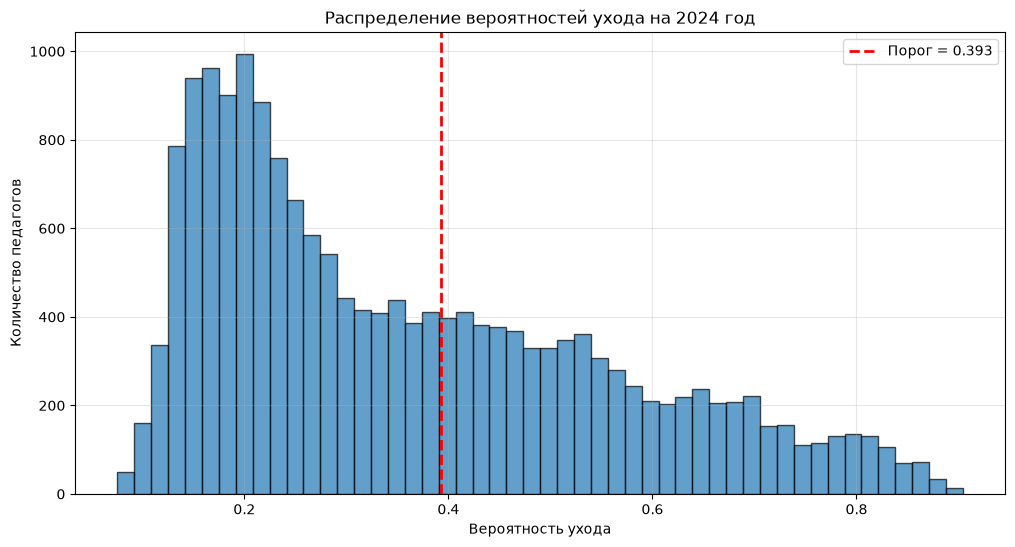


Статистика вероятностей:
count    17933.000000
mean         0.360091
std          0.194756
min          0.075631
25%          0.197558
50%          0.305859
75%          0.496022
max          0.904284
Name: prob_leave, dtype: float64


In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# Гистограмма вероятностей
plt.hist(forecast_df["prob_leave"], bins=50, alpha=0.7, edgecolor='black')
plt.axvline(optimal_threshold, color='red', linestyle='--', linewidth=2, label=f'Порог = {optimal_threshold:.3f}')
plt.xlabel('Вероятность ухода')
plt.ylabel('Количество педагогов')
plt.title('Распределение вероятностей ухода на 2024 год')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Статистика
print(f"\nСтатистика вероятностей:")
print(forecast_df["prob_leave"].describe())

### Анализ группы риска по школам
Посмотрим, в каких школах больше всего педагогов в группе риска:

In [12]:
forecast_full = forecast_df.merge(
    df[df['year'] == 2024][['id', 'school_num', 'district']], 
    on='id', 
    how='left'
)

MIN_SCHOOL_SIZE = 15  # минимум педагогов для значимости

school_risk = (
    forecast_full.groupby(['school_num', 'district'])
    .agg(
        total_teachers=('id', 'count'),
        risk_teachers=('risk_group', 'sum'),
        avg_prob=('prob_leave', 'mean')
    )
    .reset_index()
)

school_risk['risk_share'] = school_risk['risk_teachers'] / school_risk['total_teachers']

# Фильтруем малые школы
school_risk = school_risk[school_risk['total_teachers'] >= MIN_SCHOOL_SIZE]
school_risk = school_risk.sort_values('risk_share', ascending=False)

print(f"Школы с наибольшей долей группы риска (≥ {MIN_SCHOOL_SIZE} педагогов):")
school_risk.head(15)

Школы с наибольшей долей группы риска (≥ 15 педагогов):


,school_num,district,total_teachers,risk_teachers,avg_prob,risk_share
2,9,Западный округ,23,22,0.667453,0.956522
250,495,Восточный округ,31,26,0.569180,0.838710
1,4,Восточный округ,23,18,0.487827,0.782609
260,529,Восточный округ,65,47,0.512910,0.723077
261,530,Восточный округ,21,15,0.440228,0.714286
262,531,Северный округ,42,28,0.475734,0.666667
153,302,Инновационный округ,55,36,0.483654,0.654545
124,252,Восточный округ,31,20,0.450534,0.645161
224,446,Северный округ,147,91,0.480028,0.619048
19,36,Инновационный округ,25,15,0.451500,0.600000


## Итоги моделирования

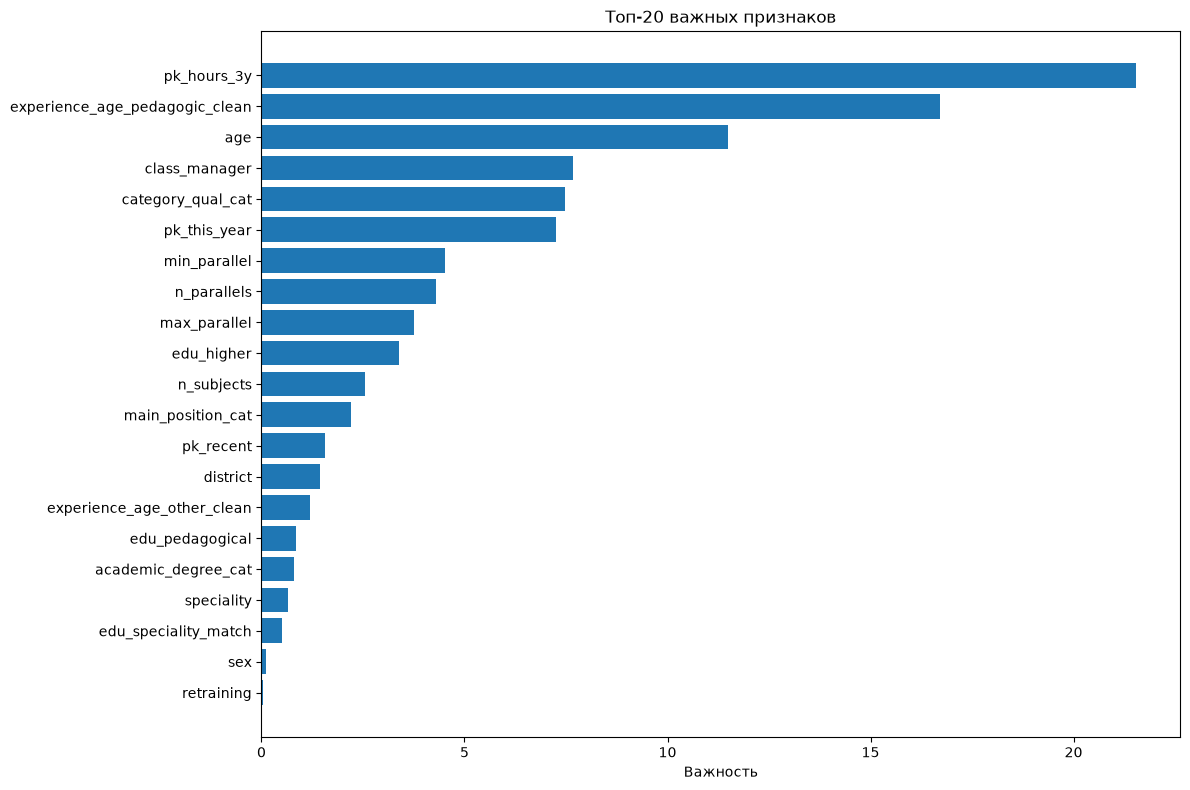

,feature,importance
14,pk_hours_3y,21.544498
1,experience_age_pedagogic_clean,16.718343
0,age,11.498270
8,class_manager,7.665855
18,category_qual_cat,7.469075
13,pk_this_year,7.262067
5,min_parallel,4.513662
4,n_parallels,4.286824
6,max_parallel,3.760889
9,edu_higher,3.380571


In [13]:
# Важность признаков
importance = model.get_feature_importance(train_pool_full)
feat_imp = pd.DataFrame({
    'feature': features,
    'importance': importance
}).sort_values('importance', ascending=False)

plt.figure(figsize=(12, 8))
plt.barh(feat_imp['feature'][::-1], feat_imp['importance'][::-1])
plt.xlabel('Важность')
plt.title('Топ-20 важных признаков')
plt.tight_layout()
plt.show()

feat_imp.head(20)

In [14]:
# Заранее вычисляем precision для оптимального порога
prec_arr, rec_arr, thr_arr = precision_recall_curve(y_test, y_test_proba)
valid_idx = np.where(rec_arr[:-1] >= target_recall)[0]
if len(valid_idx) > 0:
    best_i = valid_idx[np.argmax(prec_arr[:-1][valid_idx])]
    opt_precision = prec_arr[best_i]
    opt_recall = rec_arr[best_i]
else:
    opt_precision, opt_recall = 0.0, 0.0

summary = pd.DataFrame({
    "Показатель": [
        "Модель",
        "Сплит",
        "Лучшие параметры (Optuna)",
        "Лучшая итерация",
        "ROC-AUC (тест 2023)",
        "PR-AUC (тест 2023)",
        "Порог группы риска",
        "Recall (группа риска)",
        "Precision (группа риска)",
        "Прогноз на 2024",
        "В группе риска",
    ],
    "Значение": [
        "CatBoost + Optuna",
        "2022 → 2023 (временной)",
        str(best_params),
        str(model.best_iteration_),
        f"{model.best_score_['validation']['AUC']:.4f}",
        f"{pr_auc(rec_arr, prec_arr):.4f}",
        f"{optimal_threshold:.3f}",
        f"{opt_recall:.1%}",
        f"{opt_precision:.1%}",
        f"{len(forecast_df)} педагогов",
        f"{forecast_df['risk_group'].sum()} ({forecast_df['risk_group'].mean():.1%})",
    ]
})

summary

,Показатель,Значение
0,Модель,CatBoost + Optuna
1,Сплит,2022 → 2023 (временной)
2,Лучшие параметры (Optuna),"{'iterations': 225, 'learning_rate': 0.0772063..."
3,Лучшая итерация,109
4,ROC-AUC (тест 2023),0.7195
5,PR-AUC (тест 2023),0.2893
6,Порог группы риска,0.393
7,Recall (группа риска),70.1%
8,Precision (группа риска),22.7%
9,Прогноз на 2024,17933 педагогов


## Сохранение артефактов

Сохраняем модель, параметры, порог и метрики.
Вкладки «Прогноз» и «What-if» в дашборде читают эти файлы.

In [15]:
model.save_model(MODEL_DIR / "catboost_churn.cbm")

metadata = {
    "schema_version": 1,
    "task": "binary_leave",
    "target": "target",
    "positive_class": 1,
    "features": features,
    "categorical_features": categorical,
    "classes": [int(value) for value in model.classes_],
    "training_years": [2022],
    "evaluation_year": 2023,
    "evaluation_used_for_selection": True,
    "forecast_year": 2024,
    "evaluation_threshold": float(optimal_threshold),
    "metrics": {"roc_auc": float(roc_auc_score(y_test, y_test_proba))},
}
(MODEL_DIR / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
forecast_df.to_parquet(MODEL_DIR / "forecast_2024.parquet", index=False)

print("Сохранены catboost_churn.cbm, metadata.json и forecast_2024.parquet в", MODEL_DIR)


Сохранено:
  models\catboost_churn.cbm
  models\artifacts.pkl
  models\forecast_2024.parquet
